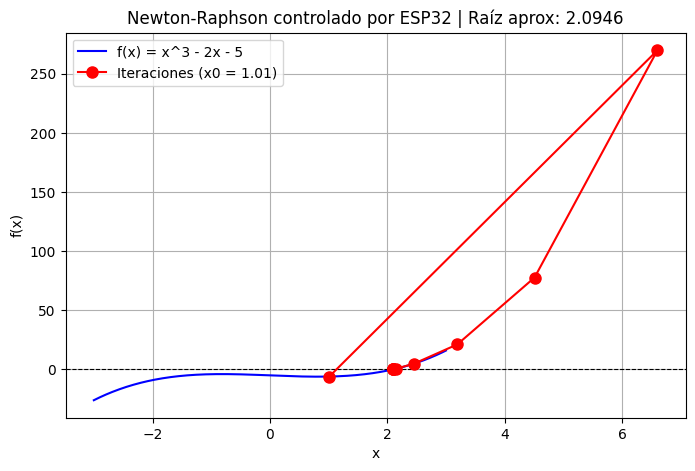

In [ ]:
import requests
import matplotlib.pyplot as plt
import numpy as np
import time
from IPython.display import clear_output

# URL ngrok
esp32URL = "https://ladder-thee-slaw.ngrok-free.dev"


#funcionOriginal
def f(x):
    return x**3 - 2*x - 5


# derivada de la funcionOriginal
def df(x):
    return 3*x**2 - 2

def newtonRaphson(x0, tol=1e-6, maxIter=10):
    x = x0
    history = [x]
    for i in range(maxIter):
        fx = f(x)
        dfx = df(x)
        if abs(dfx) < 1e-12:
            break
        xNext = x - fx / dfx
        history.append(xNext)
        if abs(xNext - x) < tol:
            break
        x = xNext
    return history

# Bucle
plt.ion()
fig, ax = plt.subplots(figsize=(8, 5))
xVals = np.linspace(-3, 3, 400)
yVals = f(xVals)

print("¡Listo para recibir datos del ESP32! Gira el potenciómetro...")

# Hará 10 lecturas consecutivas de prueba
for step in range(10):
    try:
        response = requests.get(esp32URL, timeout=3)
        data = response.json()
        x0 = data["x0"]

        history = newtonRaphson(x0)

        ax.clear()
        ax.plot(xVals, yVals, label="f(x) = x^3 - 2x - 5", color="blue")
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

        # Graficar iteraciones
        hx = np.array(history)
        hy = f(hx)
        ax.plot(hx, hy, 'ro-', label=f"Iteraciones (x0 = {x0:.2f})", markersize=8)

        ax.set_title(f"Newton-Raphson controlado por ESP32 | Raíz aprox: {history[-1]:.4f}")
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.grid(True)
        ax.legend()

        display(fig)
        clear_output(wait=True)
        time.sleep(2)

    # Mensaje de error
    except Exception as e:
        print(f"Error de conexión con el ESP32: {e}")
        break

plt.ioff()